In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt


def read_spectra(file_path: str) -> tuple[np.ndarray, np.ndarray]:
    """
    Reads spectral data from a file and returns the wavelengths and intensities.

    Parameters:
    file_path (str): The path to the spectral data file.

    Returns:
    tuple: A tuple containing two numpy arrays: (wavelengths, intensities).
    """
    with open(file_path, 'r') as f:
        lines = f.readlines()
    while lines[0].strip('\n') != ">>>>>Begin Spectral Data<<<<<":
        lines.pop(0)
    lines.pop(0)  # Remove the ">>>>>Begin Spectral Data<<<<<
    wavelengths = []
    intensities = []
    for line in lines:
        parts = line.split()
        wavelengths.append(float(parts[0]))
        intensities.append(float(parts[1]))
    return np.array(wavelengths), np.array(intensities)

In [2]:
folder = "assets/data/"

glass_spectra = []
pva_spectra = []
pva_cb_spectra = []
auni_spectra = []
for filename in os.listdir(folder):
    if "glass" in filename:
        glass_spectra.append(read_spectra(os.path.join(folder, filename)))
    elif "pva" in filename and "cb" not in filename:
        pva_spectra.append(read_spectra(os.path.join(folder, filename)))
    elif "pva" in filename and "cb" in filename:
        pva_cb_spectra.append(read_spectra(os.path.join(folder, filename)))
    elif "auni" in filename:
        auni_spectra.append(read_spectra(os.path.join(folder, filename)))

# Calculate the average spectra for each material
glass_trans = np.mean([s[1] for s in glass_spectra], axis=0)
pva_trans = np.mean([s[1] for s in pva_spectra], axis=0)
pva_cb_trans = np.mean([s[1] for s in pva_cb_spectra], axis=0)
auni_trans = np.mean([s[1] for s in auni_spectra], axis=0)

/var/folders/44/62vjt8dx0sd5w6cnwjv2k5gc0000gn/T/ipykernel_93632/1588396910.py:3: RuntimeWarning: invalid value encountered in log10
  cb_absorp = -np.log10(pva_cb_trans / pva_trans)


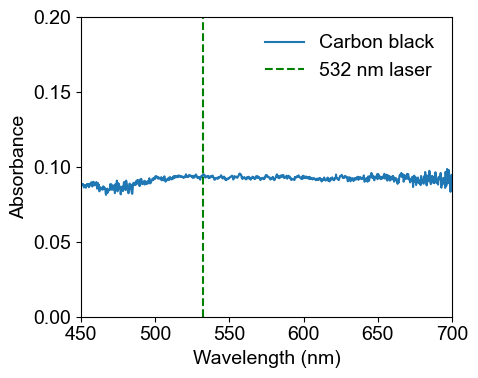

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
plt.rcParams.update({'font.size': 14, 'font.family': 'Arial'})
cb_absorp = -np.log10(pva_cb_trans / pva_trans)
wavelengths = glass_spectra[0][0]  # Assuming all spectra have the same wavelengths
ax.plot(wavelengths, cb_absorp, label="Carbon black")
ax.axvline(532, color="green", linestyle="--", label="532 nm laser")
ax.set_xlim(450, 700)
ax.set_ylim(0, 0.2)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Absorbance")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("assets/figure/cb_absorption_spectra.png", dpi=300)

In [3]:
folder = "assets/data/"

glass_spectra = []
auni_spectra = []
auni4_spectra = []
glass_old_spectra = []
for filename in os.listdir(folder):
    if "glass_new" in filename:
        glass_spectra.append(read_spectra(os.path.join(folder, filename)))
    elif "auni_10nm" in filename:
        auni_spectra.append(read_spectra(os.path.join(folder, filename)))
    elif "auni_HR" in filename:
        auni4_spectra.append(read_spectra(os.path.join(folder, filename)))
    elif "glass_HR" in filename:
        glass_old_spectra.append(read_spectra(os.path.join(folder, filename)))

# Calculate the average spectra for each material
glass_trans = np.mean([s[1] for s in glass_spectra], axis=0)
auni_trans = np.mean([s[1] for s in auni_spectra], axis=0)
auni4_trans = np.mean([s[1] for s in auni4_spectra], axis=0)
glass_old_spectra = np.mean([s[1] for s in glass_old_spectra], axis=0)

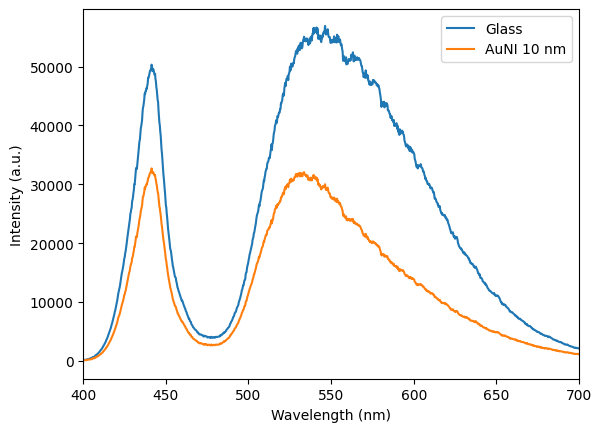

In [4]:
fig, ax = plt.subplots()
ax.plot(glass_spectra[0][0], glass_trans, label='Glass')
# ax.plot(pva_spectra[0][0], pva_trans, label='PVA')
# ax.plot(pva_cb_spectra[0][0], pva_cb_trans, label='PVA/CB')
ax.plot(auni_spectra[0][0], auni_trans, label='AuNI 10 nm')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Intensity (a.u.)')
ax.set_xlim(400, 700)
ax.legend()
fig.savefig("assets/figure/transmission1.png", dpi=600)

/var/folders/44/62vjt8dx0sd5w6cnwjv2k5gc0000gn/T/ipykernel_92358/1990522476.py:2: RuntimeWarning: invalid value encountered in log10
  auni_absorp = -np.log10(auni_trans / glass_trans)
/var/folders/44/62vjt8dx0sd5w6cnwjv2k5gc0000gn/T/ipykernel_92358/1990522476.py:3: RuntimeWarning: invalid value encountered in log10
  auni4_absorp = -np.log10(auni4_trans / glass_old_spectra)


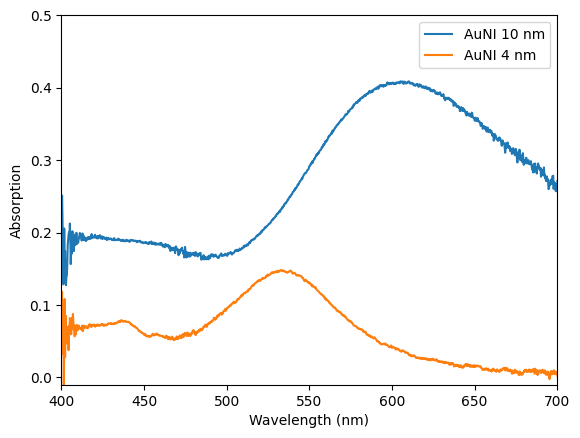

In [5]:
# cb_absorp = -np.log10(pva_cb_trans / pva_trans)
auni_absorp = -np.log10(auni_trans / glass_trans)
auni4_absorp = -np.log10(auni4_trans / glass_old_spectra)

fig, ax = plt.subplots()
# ax.plot(pva_cb_spectra[0][0], cb_absorp, label='PVA/CB')
ax.plot(auni_spectra[0][0], auni_absorp, label='AuNI 10 nm')
ax.plot(auni4_spectra[0][0], auni4_absorp, label='AuNI 4 nm')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Absorption')
ax.set_xlim(400, 700)
ax.set_ylim(-0.01, 0.50)
ax.legend()
fig.savefig("assets/figure/adsorption1.png", dpi=600)